In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

In [22]:
df=pd.read_csv('Merge_data_raw-v1.csv')

In [23]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [4]:
del df['Unnamed: 0']

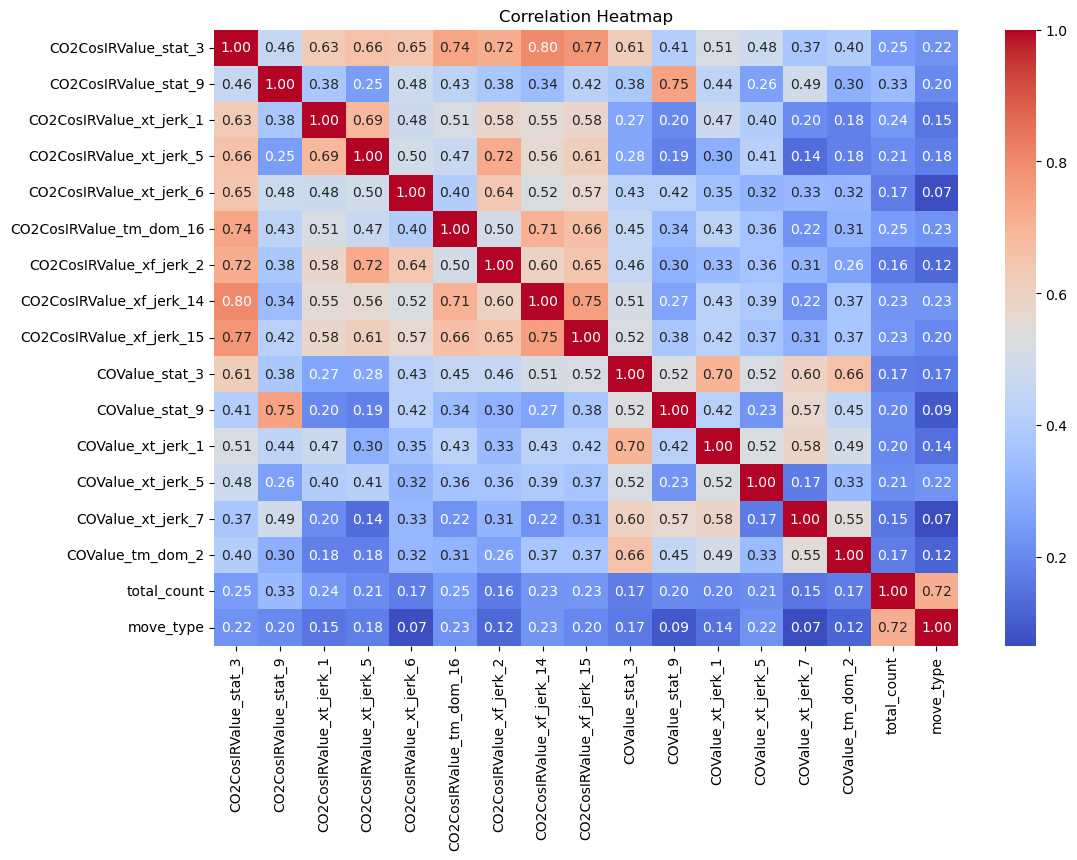

In [5]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [24]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [25]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model = DecisionTreeClassifier(max_depth=3,criterion='entropy',min_samples_split=2,min_samples_leaf=1,splitter='best')
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [9]:
np.argmax(scores)

782

In [10]:
scores[np.argmax(scores)]

0.7237113402061855

In [26]:
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix
from sklearn.model_selection import train_test_split

In [27]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=782)

In [12]:
from sklearn.model_selection import GridSearchCV

In [28]:
model = DecisionTreeClassifier(max_depth=3,criterion='entropy',min_samples_split=2,min_samples_leaf=1,splitter='best')
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [29]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.68
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.76      0.86       110
           1       0.41      0.41      0.41       117
           2       0.70      0.77      0.73       258

    accuracy                           0.68       485
   macro avg       0.70      0.65      0.67       485
weighted avg       0.69      0.68      0.68       485



In [30]:
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.6792842395044735


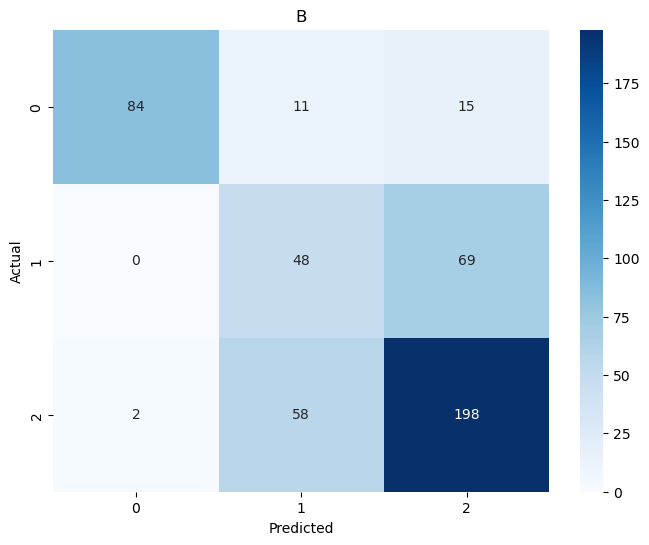

In [31]:
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('B')
plt.show()

In [19]:
dt_classifier = DecisionTreeClassifier(random_state=982)

# Define a grid of hyperparameters to search
param_grid = {
    'max_depth': [None, 1, 3, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2', None],
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'min_impurity_decrease': [0.0, 0.1, 0.2],
}

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=dt_classifier, param_grid=param_grid, scoring='accuracy', cv=5)

# Perform the grid search on the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and the best model
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Make predictions on the test set using the best model
y_pred = best_model.predict(X_test)

# Evaluate the performance of the best model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Best Parameters:", best_params)
print(f"Accuracy with Best Model: {accuracy:.2f}")
print("Classification Report:\n", report)

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'max_features': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
Accuracy with Best Model: 0.72
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.79      0.84       110
           1       0.62      0.32      0.42       117
           2       0.69      0.88      0.78       258

    accuracy                           0.72       485
   macro avg       0.73      0.66      0.68       485
weighted avg       0.72      0.72      0.70       485



/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:425: FitFailedWarning: 
2160 fits failed out of a total of 8640.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2160 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/base.py", line 1145, in wrapper
    estimator._validate_params()
  File "/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/base.py", line 638, in _validate_params
    validate_parameter_co